In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [2]:
path = '../mitbih_database/'
print(os.path.exists(path))
print(os.path.isdir(path))

True
True


In [3]:
classes = ['N', 'L', 'R', 'A', 'V']

In [4]:
records = list()
annotations = list()

In [5]:
filenames = next(os.walk(path))[2]

for f in filenames:
    filename, file_extension = f.split('.')
    
    if file_extension == 'csv':
        records.append(path + f)
    else:
        annotations.append(path + f)
        
print(records[0])
print(annotations[0])

../mitbih_database/100_record.csv
../mitbih_database/100_annotation.txt


In [6]:
data = pd.read_csv(records[0])

print(data.head())
print(data.shape)

   sample #   MLII     V5
0         0 -0.145 -0.065
1         1 -0.145 -0.065
2         2 -0.145 -0.065
3         3 -0.145 -0.065
4         4 -0.145 -0.065
(650000, 3)


In [7]:
annotations = pd.read_csv(f'{path}100_annotation.txt', sep='\t')

In [8]:
annotations['Type'].value_counts()

Type
N    2239
A      33
+       1
V       1
Name: count, dtype: int64

In [9]:
anomalies = annotations[
    annotations['Type'].isin(['A'])
]

print(anomalies)

             Time  Sample # Type  Sub  Chan  Num  Aux
8     0:00:05.678      2044    A    0     0    0  NaN
231   0:03:05.533     66792    A    0     0    0  NaN
259   0:03:28.294     74986    A    0     0    0  NaN
343   0:04:36.608     99579    A    0     0    0  NaN
442   0:05:55.792    128085    A    0     0    0  NaN
600   0:07:54.219    170719    A    0     0    0  NaN
988   0:12:56.600    279576    A    0     0    0  NaN
1079  0:14:09.192    305709    A    0     0    0  NaN
1086  0:14:14.847    307745    A    0     0    0  NaN
1104  0:14:28.958    312825    A    0     0    0  NaN
1121  0:14:42.736    317785    A    0     0    0  NaN
1126  0:14:46.731    319223    A    0     0    0  NaN
1220  0:16:03.344    346804    A    0     0    0  NaN
1236  0:16:16.336    351481    A    0     0    0  NaN
1325  0:17:27.447    377081    A    0     0    0  NaN
1395  0:18:23.708    397335    A    0     0    0  NaN
1480  0:19:32.206    421994    A    0     0    0  NaN
1483  0:19:34.494    422818 

In [10]:
annotations.iloc[8]

Time        0:00:05.678
Sample #           2044
Type                  A
Sub                   0
Chan                  0
Num                   0
Aux                 NaN
Name: 8, dtype: object

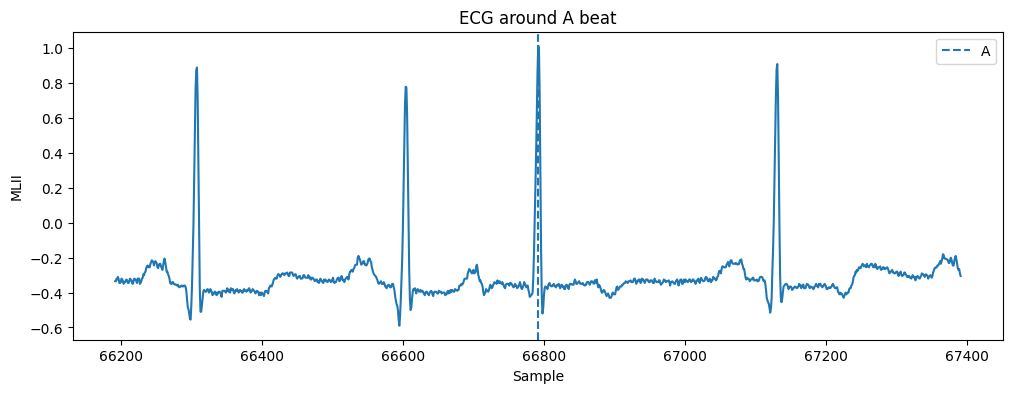

In [11]:
anomaly_sample = 66792

start = anomaly_sample - 600
end = anomaly_sample + 600

fragment = data.iloc[start:end]

plt.figure(figsize=(12, 4))

plt.plot(
    fragment['sample #'],
    fragment['MLII']
)

plt.axvline(
    anomaly_sample,
    linestyle='--',
    label='A'
)

plt.xlabel('Sample')
plt.ylabel('MLII')
plt.title('ECG around A beat')
plt.legend()

plt.show()

In [12]:
anomaly_sample = 66792

before = annotations[
    (annotations['Sample #'] < anomaly_sample) & (annotations['Sample #'] > 60000)
]['Type'].value_counts()

print(before)

Type
N    23
Name: count, dtype: int64


In [13]:
train_start = 65500
train_end = 66400

test_start = 66401
test_end = 67000

In [14]:
train_annotations = annotations[
    (annotations['Sample #'] >= train_start) &
    (annotations['Sample #'] <= train_end)
]

print(train_annotations)
print(train_annotations['Type'].value_counts())

            Time  Sample # Type  Sub  Chan  Num  Aux
227  0:03:02.639     65750    N    0     0    0  NaN
228  0:03:03.417     66030    N    0     0    0  NaN
229  0:03:04.186     66307    N    0     0    0  NaN
Type
N    3
Name: count, dtype: int64


In [15]:
signal = data['MLII']

In [16]:
signal

0        -0.145
1        -0.145
2        -0.145
3        -0.145
4        -0.145
          ...  
649995   -0.075
649996   -0.445
649997   -0.675
649998   -0.765
649999   -1.280
Name: MLII, Length: 650000, dtype: float64

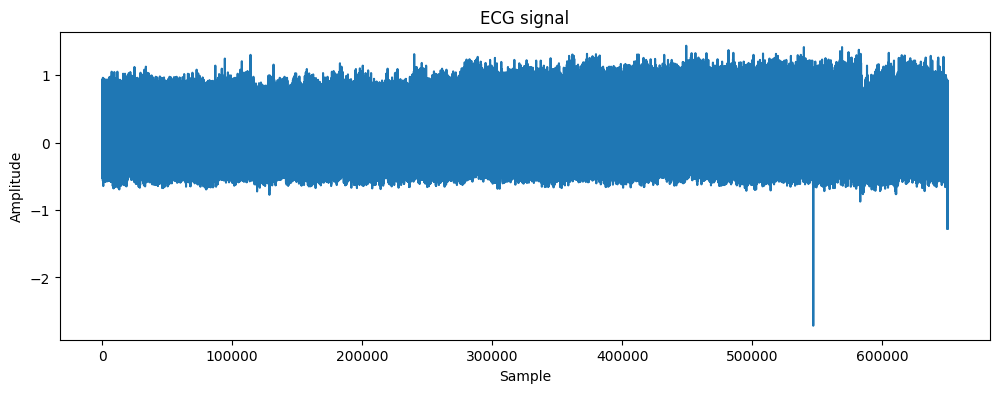

In [17]:
plt.figure(figsize=(12, 4))
plt.plot(signal)
plt.title('ECG signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

In [18]:
train = signal[train_start:train_end]
test = signal[test_start:test_end]

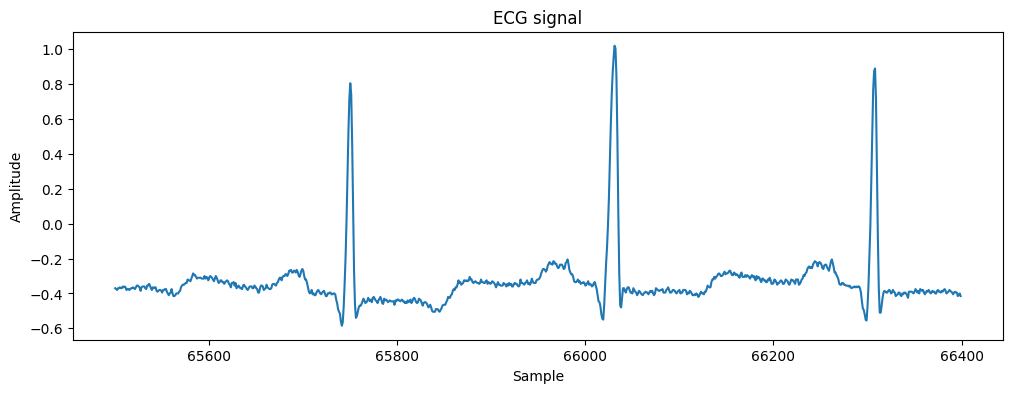

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(train)
plt.title('ECG signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

In [20]:
# from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# import matplotlib.pyplot as plt

# fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# plot_acf(signal, ax=ax[0], lags=50)
# ax[0].set_title('ACF')

# plot_pacf(signal, ax=ax[1], lags=50)
# ax[1].set_title('PACF')

# plt.tight_layout()
# plt.show()

In [ ]:
# model_init = ARIMA(train, order=(2, 0, 0))
# model_fit_init = model_init.fit()

predictions = []

history = list(train)

for value in test:
    model = ARIMA(history, order=(2, 0, 0))
    model_fit = model.fit()

    prediction = model_fit.forecast(steps=1)[0]
    predictions.append(prediction)

    history.append(value)

d:\Users\weron\Documents\studia\aaaaa praca dypl\ecg_anomaly\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Users\weron\Documents\studia\aaaaa praca dypl\ecg_anomaly\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Users\weron\Documents\studia\aaaaa praca dypl\ecg_anomaly\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Users\weron\Documents\studia\aaaaa praca dypl\ecg_anomaly\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retva

In [34]:
model_init = ARIMA(train, order=(2, 0, 0))
model_fit_init = model_init.fit()

In [36]:
train_residuals = model_fit_init.resid

In [43]:
train_residuals.head()

65500   -0.035872
65501   -0.006422
65502   -0.003644
65503    0.010983
65504   -0.011484
dtype: float64

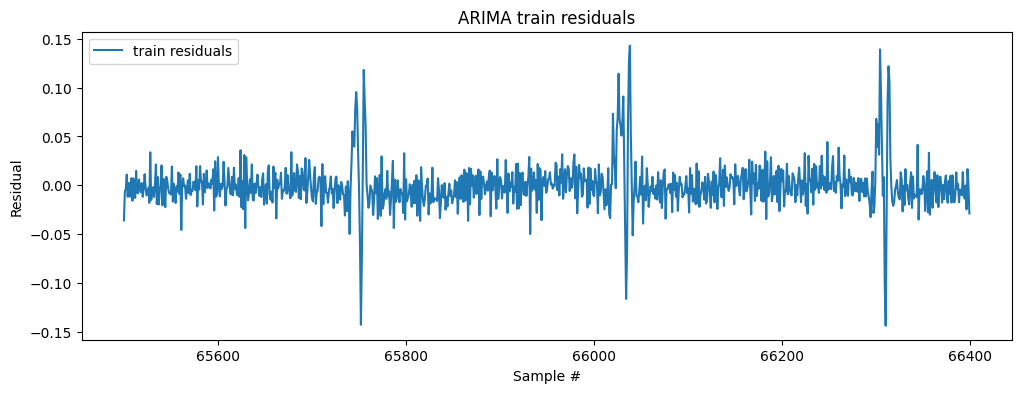

In [44]:
test_samples = test.index

plt.figure(figsize=(12, 4))

plt.plot(train_residuals, label='train residuals')

plt.xlabel('Sample #')
plt.ylabel('Residual')
plt.title('ARIMA train residuals')
plt.legend()

plt.show()

In [38]:
threshold = np.quantile(
    np.abs(train_residuals),
    0.99
)

In [41]:
print("Threshold:", threshold)
print("Max train residual:", np.abs(train_residuals).max())

Threshold: 0.10587832663106403
Max train residual: 0.1435781657348107


In [22]:
residuals = np.array(test) - np.array(predictions)

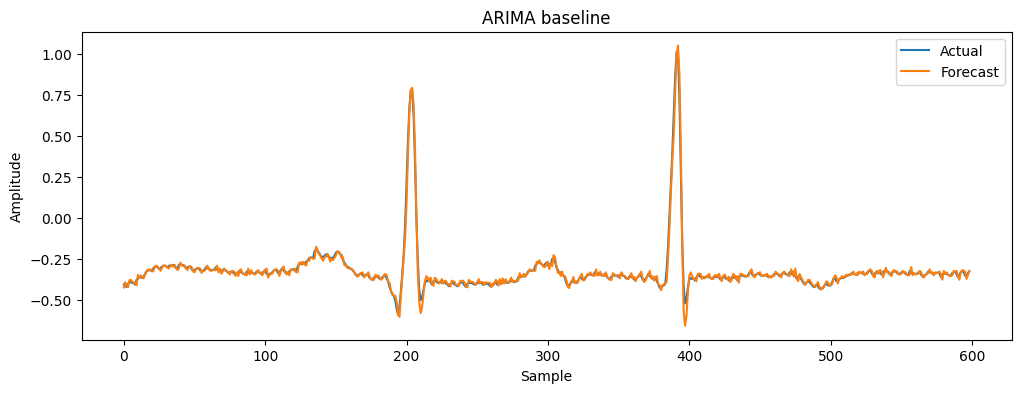

In [23]:
plt.figure(figsize=(12, 4))

plt.plot(test.values, label='Actual')
plt.plot(predictions, label='Forecast')

plt.title('ARIMA baseline')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

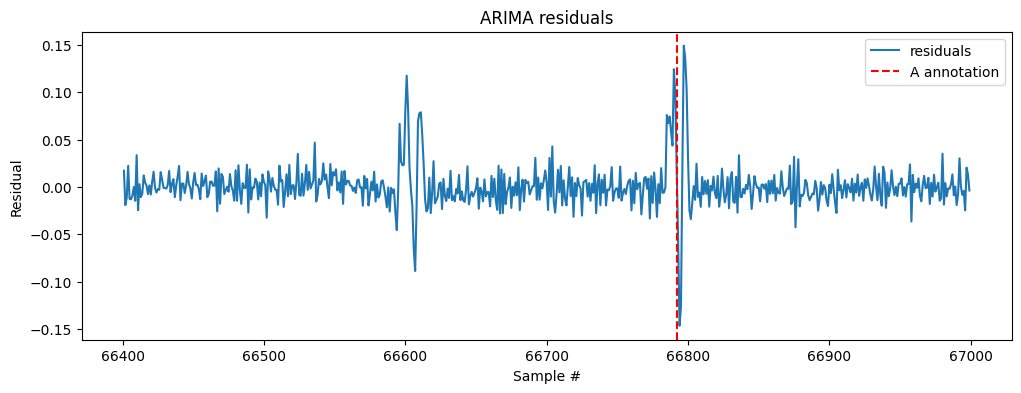

In [24]:
test_samples = test.index

plt.figure(figsize=(12, 4))

plt.plot(test_samples, residuals, label='residuals')

plt.axvline(
    anomaly_sample,
    color='red',
    linestyle='--',
    label='A annotation'
)

plt.xlabel('Sample #')
plt.ylabel('Residual')
plt.title('ARIMA residuals')
plt.legend()

plt.show()

In [40]:
residuals_df = pd.DataFrame({
    'sample': test_samples,
    'residuals': residuals
}).set_index('sample')

print(residuals_df[residuals_df['residuals'].abs() > threshold])

        residuals
sample           
66601    0.117517
66790    0.124288
66794   -0.146479
66795   -0.126529
66797    0.149114
66798    0.135972


In [31]:
annotations[
    (annotations['Sample #'] >= 66550) &
    (annotations['Sample #'] <= 66650)
][['Sample #', 'Type']]

,Sample #,Type
230,66604,N


             Time  Sample # Type  Sub  Chan  Num  Aux
8     0:00:05.678      2044    A    0     0    0  NaN
231   0:03:05.533     66792    A    0     0    0  NaN
259   0:03:28.294     74986    A    0     0    0  NaN
343   0:04:36.608     99579    A    0     0    0  NaN
442   0:05:55.792    128085    A    0     0    0  NaN
600   0:07:54.219    170719    A    0     0    0  NaN
988   0:12:56.600    279576    A    0     0    0  NaN
1079  0:14:09.192    305709    A    0     0    0  NaN
1086  0:14:14.847    307745    A    0     0    0  NaN
1104  0:14:28.958    312825    A    0     0    0  NaN
1121  0:14:42.736    317785    A    0     0    0  NaN
1126  0:14:46.731    319223    A    0     0    0  NaN
1220  0:16:03.344    346804    A    0     0    0  NaN
1236  0:16:16.336    351481    A    0     0    0  NaN
1325  0:17:27.447    377081    A    0     0    0  NaN
1395  0:18:23.708    397335    A    0     0    0  NaN
1480  0:19:32.206    421994    A    0     0    0  NaN
1483  0:19:34.494    422818 

NameError: name 'ecg' is not defined